# 02 — Analyse exploratoire et tests d'hypothèses

**Objectif** : comprendre les mécanismes de la fraude et **tester formellement** les hypothèses H1 à H5 formulées dans le [cadrage](../reports/01_cadrage.md).

**Démarche statistique**
- Tests **non paramétriques** (χ², Mann-Whitney U) : les montants financiers sont très asymétriques, l'hypothèse de normalité n'est pas tenable.
- Avec plusieurs millions d'observations, presque toute différence est « significative » (p ≈ 0). On interprète donc avant tout la **taille d'effet** (V de Cramér, r rang-bisérial, odds ratio).
- **Correction de Bonferroni** : 6 tests réalisés (H4 en compte deux), seuil α = 0,05 / 6 ≈ 0,0083.

> Les fonctions statistiques sont implémentées et testées dans `src/stats.py`, le style graphique dans `src/viz.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from src.config import RANDOM_STATE
from src.data import load_data
from src.stats import chi2_independence, mann_whitney, odds_ratio, results_table
from src.viz import (set_style, save_fig, COLOR_LEGIT, COLOR_FRAUD, CLASS_COLORS,
                     CLASS_LABELS, TEXT_SECONDARY, SEQUENTIAL_CMAP)

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

df = load_data()
print(f"{len(df):,} transactions chargées")

6,362,620 transactions chargées


## 1. Déséquilibre de la cible

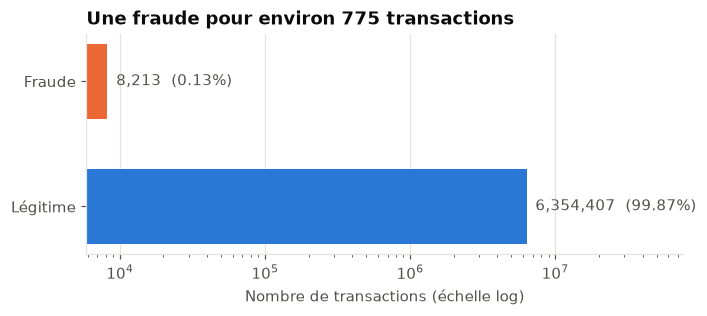

In [2]:
counts = df["isFraud"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh([CLASS_LABELS[i] for i in counts.index], counts.values,
        color=[CLASS_COLORS[i] for i in counts.index], height=0.6)
ax.set_xscale("log")
ax.set_xlabel("Nombre de transactions (échelle log)")
ax.set_title("Une fraude pour environ 775 transactions")
ax.grid(axis="y", visible=False)
for i, v in enumerate(counts.values):
    ax.text(v * 1.15, i, f"{v:,}  ({v / counts.sum():.2%})", va="center", color=TEXT_SECONDARY)
ax.set_xlim(right=counts.max() * 12)
save_fig(fig, "02_desequilibre_cible")
plt.show()

L'échelle logarithmique est indispensable : sur une échelle linéaire, la barre des fraudes serait invisible. Ce déséquilibre extrême (0,13 %) justifie le choix de la PR-AUC comme métrique principale.

## 2. H1 — La fraude dépend du type de transaction

**H0** : le type de transaction et la fraude sont indépendants.
**Test** : χ² d'indépendance, taille d'effet : V de Cramér.

In [3]:
by_type = (df.groupby("type", observed=True)["isFraud"]
             .agg(n_transactions="size", n_fraudes="sum", taux_fraude="mean")
             .sort_values("n_transactions", ascending=False))
by_type["taux_fraude_pct"] = by_type.pop("taux_fraude") * 100
by_type

,n_transactions,n_fraudes,taux_fraude_pct
type,,,
CASH_OUT,2237500,4116,0.1840
PAYMENT,2151495,0,0.0000
CASH_IN,1399284,0,0.0000
TRANSFER,532909,4097,0.7688
DEBIT,41432,0,0.0000


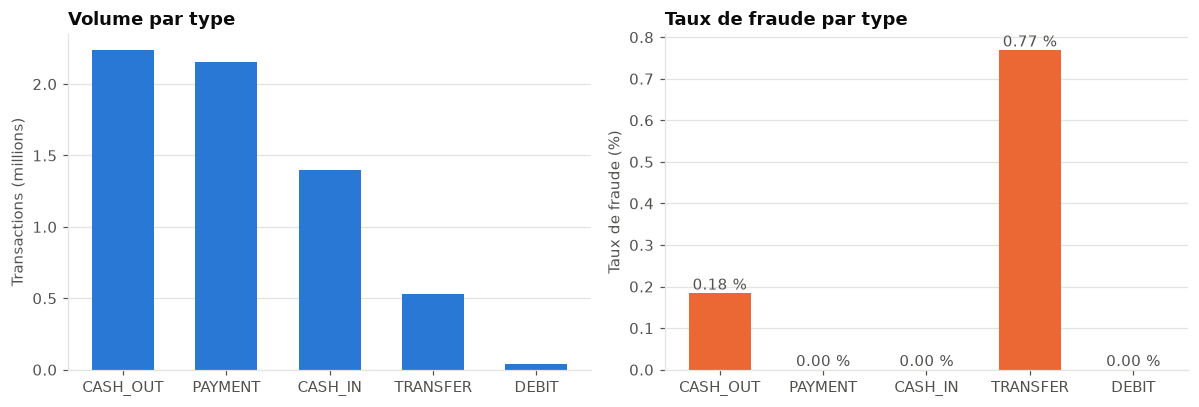

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

order = by_type.index.astype(str)
axes[0].bar(order, by_type["n_transactions"] / 1e6, color=COLOR_LEGIT, width=0.6)
axes[0].set_title("Volume par type")
axes[0].set_ylabel("Transactions (millions)")
axes[0].grid(axis="x", visible=False)

axes[1].bar(order, by_type["taux_fraude_pct"], color=COLOR_FRAUD, width=0.6)
axes[1].set_title("Taux de fraude par type")
axes[1].set_ylabel("Taux de fraude (%)")
axes[1].grid(axis="x", visible=False)
for x, v in zip(order, by_type["taux_fraude_pct"]):
    axes[1].text(x, v, f"{v:.2f} %", ha="center", va="bottom", color=TEXT_SECONDARY)

fig.tight_layout()
save_fig(fig, "02_h1_fraude_par_type")
plt.show()

In [5]:
res_h1 = chi2_independence(df["type"].astype(str), df["isFraud"])
res_h1

TestResult(test="Chi² d'indépendance", statistic=22082.53571319108, p_value=0.0, effect_name='V de Cramér', effect_size=0.05891236771716165, effect_label='négligeable')

**Interprétation H1** : la fraude n'existe que dans `TRANSFER` (0,77 %) et `CASH_OUT` (0,18 %) ; les trois autres types n'en contiennent **aucune**. H0 est rejetée (p ≈ 0).

Le V de Cramér est pourtant **négligeable** (0,06). Ce n'est pas contradictoire : le V mesure l'association sur l'ensemble des 6,3 M de lignes, or la fraude reste très rare même dans les deux types concernés (moins de 1 %). Connaître le type ne permet donc pas de *prédire* la fraude, mais il permet d'**exclure** avec certitude 56 % des transactions. La dépendance est **structurelle** : elle correspond au scénario simulé (prise de contrôle du compte → transfert vers un complice → retrait).

➡️ **Conséquence** : la suite de l'analyse se concentre sur `TRANSFER` et `CASH_OUT`. Comparer les fraudes à des paiements marchands n'aurait pas de sens et gonflerait artificiellement les différences.

In [6]:
tc = df[df["type"].isin(["TRANSFER", "CASH_OUT"])].copy()
tc["type"] = tc["type"].cat.remove_unused_categories()
fraud, legit = tc[tc["isFraud"] == 1], tc[tc["isFraud"] == 0]
print(f"Sous-population TRANSFER + CASH_OUT : {len(tc):,} transactions, "
      f"{len(fraud):,} fraudes ({tc['isFraud'].mean():.3%})")

Sous-population TRANSFER + CASH_OUT : 2,770,409 transactions, 8,213 fraudes (0.296%)


### Le scénario « transfert puis retrait » est-il traçable ?

Si les fraudeurs transfèrent vers un compte complice qui retire ensuite l'argent, le destinataire d'un `TRANSFER` frauduleux devrait réapparaître comme émetteur d'un `CASH_OUT` frauduleux.

In [7]:
dest_transfer = set(fraud.loc[fraud["type"] == "TRANSFER", "nameDest"])
orig_cashout = set(fraud.loc[fraud["type"] == "CASH_OUT", "nameOrig"])
print(f"Destinataires de TRANSFER frauduleux retrouvés comme émetteurs de CASH_OUT frauduleux : "
      f"{len(dest_transfer & orig_cashout)}")

Destinataires de TRANSFER frauduleux retrouvés comme émetteurs de CASH_OUT frauduleux : 0


Aucun lien : le simulateur ne chaîne pas les deux étapes par les identifiants. On ne pourra donc pas exploiter ce scénario via des variables de réseau ; chaque transaction doit être jugée **sur ses propres caractéristiques**.

## 3. H2 — Les montants frauduleux sont plus élevés

**H0** : les distributions des montants sont identiques pour les fraudes et les transactions légitimes (TRANSFER + CASH_OUT).
**Test** : Mann-Whitney U, taille d'effet : r rang-bisérial.

In [8]:
tc.groupby("isFraud")["amount"].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).rename(index=CLASS_LABELS)

,count,mean,std,min,25%,50%,75%,99%,max
isFraud,,,,,,,,,
Légitime,"2,762,196.0000","314,115.4962","877,144.1496",0.0100,"82,908.2325","171,034.4600","305,994.1850","2,580,263.9160","92,445,516.6400"
Fraude,"8,213.0000","1,467,967.2991","2,404,252.9472",0.0000,"127,091.3300","441,423.4400","1,517,771.4800","10,000,000.0000","10,000,000.0000"


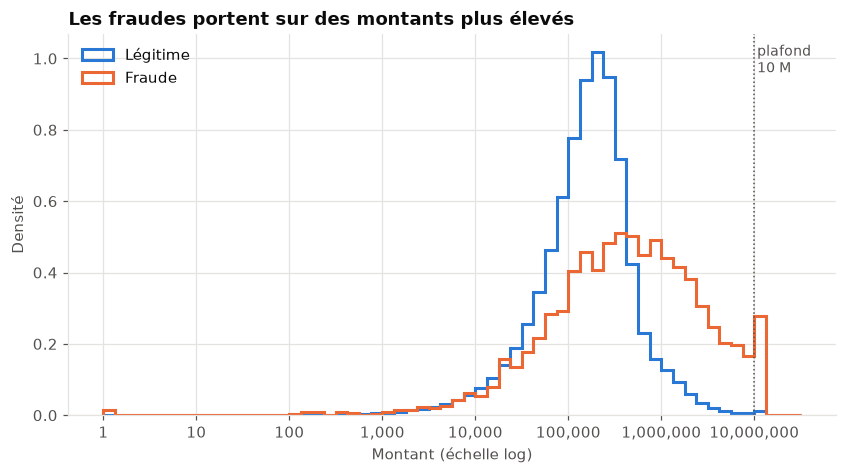

In [9]:
bins = np.linspace(0, 7.5, 61)
fig, ax = plt.subplots()
for cls, data in [(0, legit), (1, fraud)]:
    ax.hist(np.log10(data["amount"].clip(lower=1)), bins=bins, density=True,
            histtype="step", linewidth=2, color=CLASS_COLORS[cls], label=CLASS_LABELS[cls])
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{10**x:,.0f}"))
ax.set_xlabel("Montant (échelle log)")
ax.set_ylabel("Densité")
ax.set_title("Les fraudes portent sur des montants plus élevés")
ax.axvline(7, color=TEXT_SECONDARY, linestyle=":", linewidth=1)
ax.text(7.03, ax.get_ylim()[1] * 0.9, "plafond\n10 M", color=TEXT_SECONDARY, fontsize=9)
ax.legend()
save_fig(fig, "02_h2_distribution_montants")
plt.show()

In [10]:
res_h2 = mann_whitney(fraud["amount"], legit["amount"])
res_h2

TestResult(test='Mann-Whitney U', statistic=15502887890.0, p_value=0.0, effect_name='r rang-bisérial', effect_size=0.3667412029745143, effect_label='moyen')

**Interprétation H2** : le montant médian d'une fraude (441 k) est **2,6 fois** celui d'une transaction légitime du même type (171 k), et 1 % des fraudes atteignent le plafond de 10 M imposé par le simulateur. H0 est rejetée avec un **effet moyen** (r = 0,37). Les distributions se recouvrent toutefois largement : **le montant seul ne suffit pas** à séparer les classes.

## 4. H3 — Les fraudes vident le compte émetteur

On définit un **compte vidé** lorsque le montant de la transaction est égal au solde initial (non nul) de l'émetteur : `amount ≈ oldbalanceOrig > 0`.

**H0** : vider son compte est indépendant de la fraude.
**Test** : χ², tailles d'effet : V de Cramér et odds ratio.

In [11]:
tc["compte_vide"] = (tc["oldbalanceOrig"] > 0) & ((tc["amount"] - tc["oldbalanceOrig"]).abs() <= 0.01)
h3_table = pd.crosstab(tc["compte_vide"], tc["isFraud"], normalize="columns").mul(100)
h3_table.columns = [CLASS_LABELS[c] for c in h3_table.columns]
h3_table.index = ["Compte non vidé", "Compte vidé"]
h3_table.round(2)

,Légitime,Fraude
Compte non vidé,100.0000,2.3700
Compte vidé,0.0000,97.6300


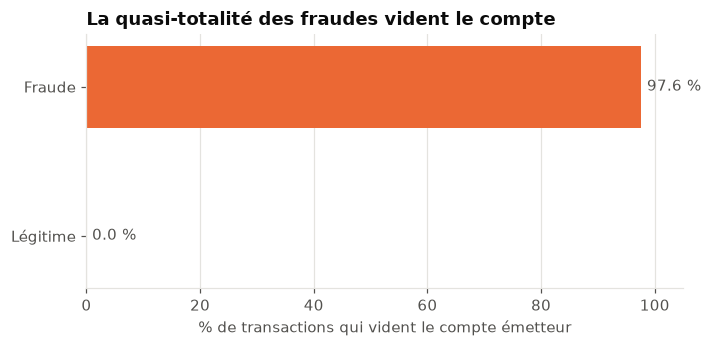

In [12]:
fig, ax = plt.subplots(figsize=(7, 3))
share = tc.groupby("isFraud")["compte_vide"].mean().mul(100)
ax.barh([CLASS_LABELS[i] for i in share.index], share.values,
        color=[CLASS_COLORS[i] for i in share.index], height=0.55)
ax.set_xlim(0, 105)
ax.set_xlabel("% de transactions qui vident le compte émetteur")
ax.set_title("La quasi-totalité des fraudes vident le compte")
ax.grid(axis="y", visible=False)
for i, v in enumerate(share.values):
    ax.text(v + 1, i, f"{v:.1f} %", va="center", color=TEXT_SECONDARY)
save_fig(fig, "02_h3_compte_vide")
plt.show()

In [13]:
res_h3 = chi2_independence(tc["compte_vide"], tc["isFraud"])
or_h3 = odds_ratio(tc["compte_vide"], tc["isFraud"])
print(f"Odds ratio : {or_h3:,.0f}")
res_h3

Odds ratio : 226,584,886


TestResult(test="Chi² d'indépendance", statistic=2704440.6810935824, p_value=0.0, effect_name='V de Cramér', effect_size=0.9880223875523949, effect_label='fort')

**Interprétation H3** : **97,6 % des fraudes** (8 018 sur 8 213) vident le compte émetteur, contre **aucune** transaction légitime (0 sur 2,76 M). H0 est rejetée avec un **effet quasi maximal** (V = 0,99).

⚠️ **Point critique** : une simple règle « `amount = oldbalanceOrig > 0` ⇒ fraude » atteindrait déjà **100 % de précision et 97,6 % de rappel**. Une telle séparation parfaite n'existe pas dans des données réelles (un client légitime peut tout à fait vider son compte) : c'est un **artefact du simulateur PaySim**, où seul le scénario de fraude transfère la totalité du solde.

➡️ Cette règle sera ajoutée comme **seconde baseline métier** (Phase 6) : un modèle de Machine Learning n'a d'intérêt que s'il fait mieux qu'elle. Elle sera aussi intégrée à l'étude de robustesse.

## 5. H4 — Les incohérences de soldes sont discriminantes

On définit les **erreurs de solde** comme l'écart entre le solde attendu et le solde observé :
- `erreur_orig = newbalanceOrig + amount − oldbalanceOrig`
- `erreur_dest = oldbalanceDest + amount − newbalanceDest`

Une transaction parfaitement cohérente a une erreur nulle.

**H0** : les erreurs de solde ont la même distribution pour les fraudes et les transactions légitimes.
**Test** : Mann-Whitney U (un test par erreur).

In [14]:
tc["erreur_orig"] = tc["newbalanceOrig"] + tc["amount"] - tc["oldbalanceOrig"]
tc["erreur_dest"] = tc["oldbalanceDest"] + tc["amount"] - tc["newbalanceDest"]

summary = tc.groupby("isFraud").agg(
    erreur_orig_nulle=("erreur_orig", lambda s: (s.abs() <= 0.01).mean() * 100),
    erreur_dest_nulle=("erreur_dest", lambda s: (s.abs() <= 0.01).mean() * 100),
    erreur_orig_mediane=("erreur_orig", "median"),
    erreur_dest_mediane=("erreur_dest", "median"),
).rename(index=CLASS_LABELS)
summary

,erreur_orig_nulle,erreur_dest_nulle,erreur_orig_mediane,erreur_dest_mediane
isFraud,,,,
Légitime,9.4190,77.4239,"144,200.8250",0.0000
Fraude,99.4521,43.5042,0.0000,"2,231.4600"


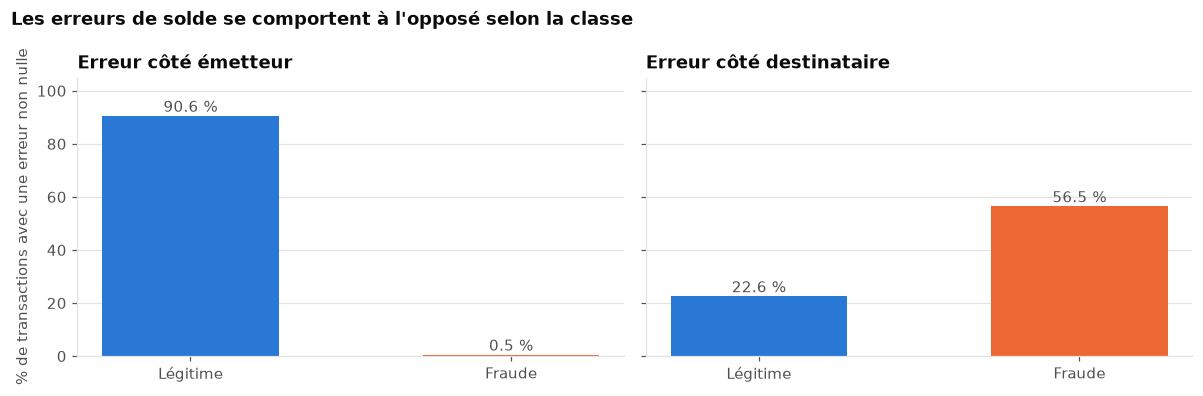

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, col, title in [(axes[0], "erreur_orig", "Erreur côté émetteur"),
                       (axes[1], "erreur_dest", "Erreur côté destinataire")]:
    share = tc.groupby("isFraud")[col].apply(lambda s: (s.abs() > 0.01).mean() * 100)
    ax.bar([CLASS_LABELS[i] for i in share.index], share.values,
           color=[CLASS_COLORS[i] for i in share.index], width=0.55)
    ax.set_title(title)
    ax.set_ylim(0, 105)
    ax.grid(axis="x", visible=False)
    for i, v in enumerate(share.values):
        ax.text(i, v + 1.5, f"{v:.1f} %", ha="center", color=TEXT_SECONDARY)
axes[0].set_ylabel("% de transactions avec une erreur non nulle")
fig.suptitle("Les erreurs de solde se comportent à l'opposé selon la classe", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_h4_erreurs_solde")
plt.show()

In [16]:
res_h4_orig = mann_whitney(fraud.index.map(tc["erreur_orig"]), legit.index.map(tc["erreur_orig"]))
res_h4_dest = mann_whitney(fraud.index.map(tc["erreur_dest"]), legit.index.map(tc["erreur_dest"]))
pd.DataFrame({"erreur_orig": res_h4_orig.to_dict(), "erreur_dest": res_h4_dest.to_dict()}).T

,test,statistic,p_value,effect_name,effect_size,effect_label
erreur_orig,Mann-Whitney U,"1,209,058,476.0000",0.0000,r rang-bisérial,-0.8934,fort
erreur_dest,Mann-Whitney U,"16,983,030,456.5000",0.0000,r rang-bisérial,0.4972,moyen


**Interprétation H4** : les deux erreurs se comportent de façon **opposée** selon la classe :
- côté **émetteur**, 99,5 % des fraudes ont une erreur nulle (le compte est vidé proprement), contre seulement 9,4 % des transactions légitimes (exécutées malgré un solde insuffisant). Effet **fort** (r = −0,89) ;
- côté **destinataire**, c'est l'inverse : 56,5 % des fraudes présentent une erreur, contre 22,6 % des transactions légitimes. Effet **moyen** (r = 0,50).

H0 est rejetée pour les deux variables, avec des effets supérieurs à celui du montant (H2). Ces variables seront construites dans le feature engineering.

⚠️ Comme pour H3, ces écarts sont des **artefacts du simulateur** (règles de mise à jour des soldes). Un modèle qui s'appuie dessus serait performant ici, mais pas forcément transposable à des données réelles.

## 6. Analyse de fuite de données : les destinataires à soldes nuls

La Phase 2 a montré que les `TRANSFER` vers des clients dont les soldes avant et après sont nuls étaient presque tous frauduleux. Regardons ce signal plus précisément.

In [17]:
tc["dest_soldes_nuls"] = (tc["oldbalanceDest"] == 0) & (tc["newbalanceDest"] == 0) & (tc["amount"] > 0)
leak = tc.groupby(["type", "dest_soldes_nuls"], observed=True)["isFraud"].agg(["size", "sum", "mean"])
leak.columns = ["n_transactions", "n_fraudes", "taux_fraude"]
leak

n_transactions  n_fraudes  taux_fraude
type     dest_soldes_nuls                                        
CASH_OUT False                    2235898       4114       0.0018
         True                        1602          2       0.0012
TRANSFER False                     528735         29       0.0001
         True                        4174       4068       0.9746

In [18]:
share_fraud_flag = tc.loc[tc["isFraud"] == 1, "dest_soldes_nuls"].mean()
print(f"Part des fraudes avec soldes destinataire nuls : {share_fraud_flag:.1%}")
print(f"Odds ratio : {odds_ratio(tc['dest_soldes_nuls'], tc['isFraud']):,.0f}")

Part des fraudes avec soldes destinataire nuls : 49.6%


Odds ratio : 1,589


**Discussion** :
- Parmi les `TRANSFER` dont le destinataire a des soldes nuls avant **et** après, **97,5 % sont des fraudes** (4 068 sur 4 174). Ce cas concerne la moitié des fraudes (49,6 %).
- Un destinataire qui reçoit de l'argent devrait voir son solde augmenter : ces soldes nuls sont **comptablement impossibles**. C'est la façon dont le simulateur traite les comptes de fraudeurs.
- Est-ce une **fuite de données** ? Au sens strict, non : `oldbalanceDest` et `newbalanceDest` sont connus au moment de la transaction (aucune information future n'est utilisée). Mais c'est un **artefact de simulation** qui n'existerait pas dans un système réel.

➡️ **Décision méthodologique** : les variables de solde sont conservées, mais on mènera une **étude de robustesse** (Phase 7) en entraînant un modèle **sans** les variables issues de ces artefacts (soldes destinataires, erreurs de solde, indicateur « compte vidé »), pour mesurer à quel point la performance en dépend. C'est plus honnête que de présenter un score parfait sans le questionner.

## 7. H5 — Le taux de fraude varie selon l'heure

`step` représente une heure de simulation ; on en déduit l'heure de la journée (`step % 24`) et le jour (`step // 24`).

**H0** : l'heure de la journée et la fraude sont indépendantes (TRANSFER + CASH_OUT).
**Test** : χ², taille d'effet : V de Cramér.

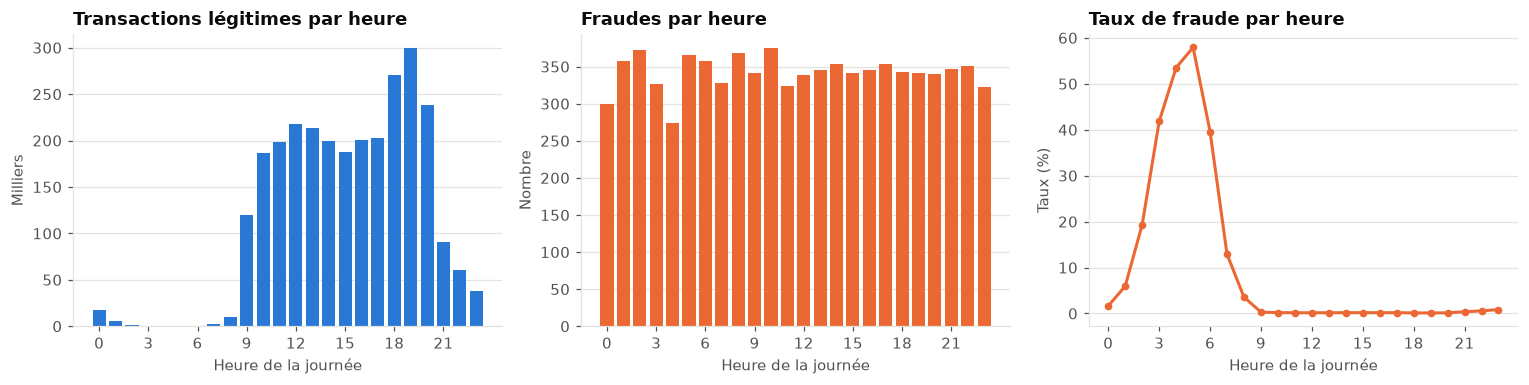

In [19]:
tc["heure"] = tc["step"] % 24
tc["jour"] = tc["step"] // 24

hourly = tc.groupby(["heure", "isFraud"]).size().unstack(fill_value=0)
hourly_rate = tc.groupby("heure")["isFraud"].mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].bar(hourly.index, hourly[0] / 1e3, color=COLOR_LEGIT, width=0.8)
axes[0].set_title("Transactions légitimes par heure")
axes[0].set_ylabel("Milliers")
axes[1].bar(hourly.index, hourly[1], color=COLOR_FRAUD, width=0.8)
axes[1].set_title("Fraudes par heure")
axes[1].set_ylabel("Nombre")
axes[2].plot(hourly_rate.index, hourly_rate.values, color=COLOR_FRAUD, marker="o", markersize=4)
axes[2].set_title("Taux de fraude par heure")
axes[2].set_ylabel("Taux (%)")
for ax in axes:
    ax.set_xlabel("Heure de la journée")
    ax.set_xticks(range(0, 24, 3))
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save_fig(fig, "02_h5_profil_horaire")
plt.show()

In [20]:
res_h5 = chi2_independence(tc["heure"], tc["isFraud"])
night = tc["heure"].between(0, 6)
print(f"Taux de fraude la nuit (0h-6h) : {tc.loc[night, 'isFraud'].mean():.2%}  |  "
      f"le jour : {tc.loc[~night, 'isFraud'].mean():.2%}")
res_h5

Taux de fraude la nuit (0h-6h) : 8.13%  |  le jour : 0.21%


TestResult(test="Chi² d'indépendance", statistic=263619.28817415325, p_value=0.0, effect_name='V de Cramér', effect_size=0.30847263751744347, effect_label='moyen')

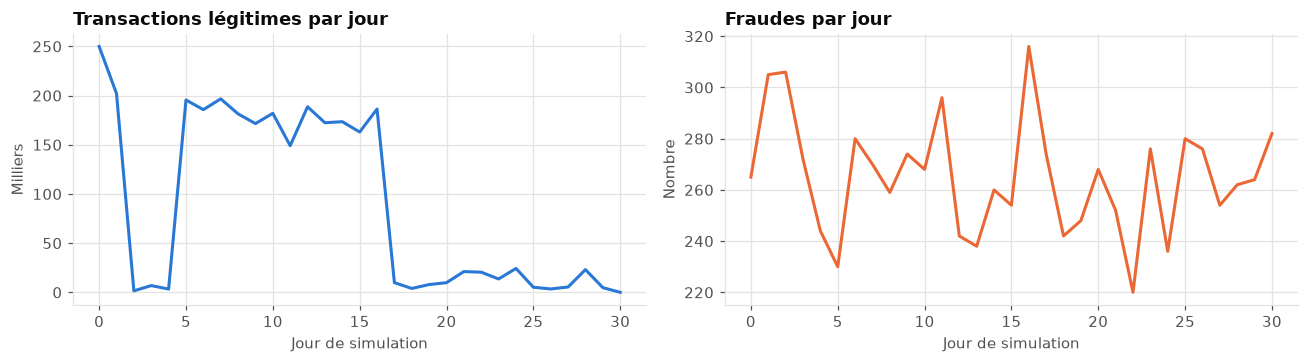

In [21]:
daily = tc.groupby(["jour", "isFraud"]).size().unstack(fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharex=True)
axes[0].plot(daily.index, daily[0] / 1e3, color=COLOR_LEGIT)
axes[0].set_title("Transactions légitimes par jour")
axes[0].set_ylabel("Milliers")
axes[1].plot(daily.index, daily[1], color=COLOR_FRAUD)
axes[1].set_title("Fraudes par jour")
axes[1].set_ylabel("Nombre")
for ax in axes:
    ax.set_xlabel("Jour de simulation")
fig.tight_layout()
save_fig(fig, "02_profil_journalier")
plt.show()

**Interprétation H5** : l'activité légitime suit un fort **cycle jour/nuit**, tandis que la fraude est répartie de manière **à peu près uniforme** sur les 24 heures. Conséquence : la nuit (0h-6h), quand l'activité légitime s'effondre, le taux de fraude atteint **8,1 %** en moyenne (avec un pic proche de **60 %** vers 5h) contre **0,2 %** le jour. H0 est rejetée avec un **effet moyen** (V = 0,31). L'heure de la journée sera conservée comme variable.

**Non-stationnarité** : le profil journalier montre que l'activité légitime est forte les jours 0-1 et 5-16, puis s'effondre à partir du jour 17 (de ~180 000 à quelques milliers de transactions par jour), alors que la fraude reste stable (~260 par jour). Le **taux de fraude varie donc d'un facteur 10 à 100** selon la période.

➡️ **Conséquence majeure pour la Phase 4** : un split temporel naïf (test = dernière semaine) donnerait un jeu de test avec un taux de fraude sans commune mesure avec celui d'entraînement, ce qui fausserait l'évaluation et le choix du seuil. Le découpage temporel devra être conçu **en tenant compte de cette dérive**, et le choix sera justifié explicitement.

## 8. Corrélations entre variables numériques

Corrélation de **Spearman** (basée sur les rangs, robuste aux valeurs extrêmes), calculée sur TRANSFER + CASH_OUT.

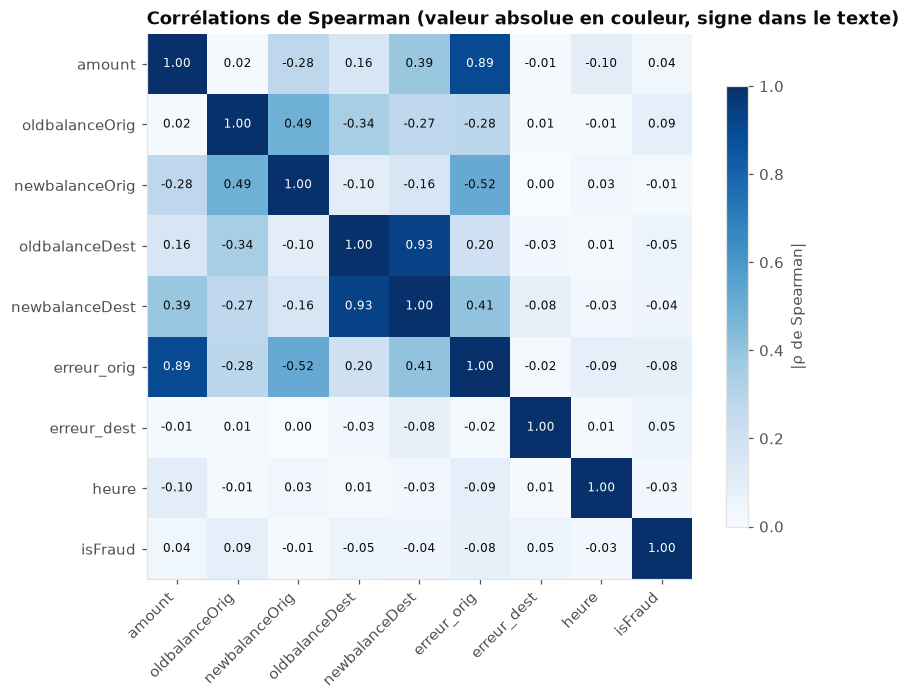

In [22]:
num_cols = ["amount", "oldbalanceOrig", "newbalanceOrig", "oldbalanceDest", "newbalanceDest",
            "erreur_orig", "erreur_dest", "heure", "isFraud"]
sample = tc[num_cols].sample(n=500_000, random_state=RANDOM_STATE)
corr = sample.corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr.abs(), cmap=SEQUENTIAL_CMAP, vmin=0, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=45, ha="right")
ax.set_yticks(range(len(num_cols)), num_cols)
ax.grid(False)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.8, label="|ρ de Spearman|")
ax.set_title("Corrélations de Spearman (valeur absolue en couleur, signe dans le texte)")
save_fig(fig, "02_correlations_spearman")
plt.show()

In [23]:
corr["isFraud"].drop("isFraud").sort_values(key=abs, ascending=False).to_frame("ρ avec isFraud")

,ρ avec isFraud
oldbalanceOrig,0.0865
erreur_orig,-0.0844
oldbalanceDest,-0.0547
erreur_dest,0.0547
newbalanceDest,-0.0433
amount,0.0370
heure,-0.0311
newbalanceOrig,-0.0143


Les soldes émetteurs avant/après et destinataires avant/après sont fortement corrélés entre eux (redondance). Les corrélations linéaires avec la cible restent modestes : la fraude dépend de **combinaisons** de variables (ex. « solde vidé ET erreur côté destinataire »), ce que des modèles non linéaires (arbres, boosting) captureront mieux qu'une régression logistique.

## 9. Synthèse des tests d'hypothèses

In [24]:
results = {
    "H1 — type de transaction": res_h1,
    "H2 — montant": res_h2,
    "H3 — compte vidé": res_h3,
    "H4a — erreur solde émetteur": res_h4_orig,
    "H4b — erreur solde destinataire": res_h4_dest,
    "H5 — heure de la journée": res_h5,
}
synthesis = results_table(results, alpha=0.05)
print(f"Seuil de Bonferroni : α = {synthesis.attrs['alpha_bonferroni']:.4f}")
synthesis[["test", "p_value", "effect_name", "effect_size", "effect_label", "significatif"]]

Seuil de Bonferroni : α = 0.0083


,test,p_value,effect_name,effect_size,effect_label,significatif
H1 — type de transaction,Chi² d'indépendance,0.0000,V de Cramér,0.0589,négligeable,True
H2 — montant,Mann-Whitney U,0.0000,r rang-bisérial,0.3667,moyen,True
H3 — compte vidé,Chi² d'indépendance,0.0000,V de Cramér,0.9880,fort,True
H4a — erreur solde émetteur,Mann-Whitney U,0.0000,r rang-bisérial,-0.8934,fort,True
H4b — erreur solde destinataire,Mann-Whitney U,0.0000,r rang-bisérial,0.4972,moyen,True
H5 — heure de la journée,Chi² d'indépendance,0.0000,V de Cramér,0.3085,moyen,True


## 10. Conclusions

### Bilan des hypothèses

| # | Hypothèse | Résultat | Taille d'effet | Conséquence |
|---|---|---|---|---|
| H1 | La fraude dépend du type | ✅ Validée | V = 0,06 (négligeable sur l'ensemble, mais 0 fraude dans 3 types sur 5) | Filtrer sur `TRANSFER` / `CASH_OUT` |
| H2 | Montants frauduleux plus élevés | ✅ Validée | r = 0,37 (moyen) | Variable utile mais insuffisante seule |
| H3 | Les fraudes vident le compte | ✅ Validée | V = 0,99 (quasi parfait) | Seconde baseline métier ; artefact à surveiller |
| H4 | Incohérences de soldes discriminantes | ✅ Validée | r = −0,89 (émetteur) / 0,50 (destinataire) | Variables d'erreur de solde à construire |
| H5 | Le taux de fraude dépend de l'heure | ✅ Validée | V = 0,31 (moyen) | Variable « heure » à construire |

Toutes les hypothèses sont validées au seuil de Bonferroni (α ≈ 0,0083), mais avec des **tailles d'effet très différentes**, ce qui guide la priorisation des variables.

### Enseignements clés
1. **La fraude suit un scénario très stéréotypé** : `TRANSFER` ou `CASH_OUT`, totalité du solde, souvent la nuit, vers un compte aux soldes incohérents.
2. **Plusieurs signaux sont des artefacts du simulateur** (compte vidé, soldes destinataires nuls, erreurs de solde) : ils rendront la détection très facile, peut-être trop. La valeur ajoutée du projet sera de **le démontrer et de le quantifier** (baseline « compte vidé », étude de robustesse).
3. **Le taux de fraude n'est pas stationnaire** : le protocole de découpage temporel doit être conçu avec soin.
4. **Les corrélations linéaires avec la cible sont faibles** : la fraude repose sur des combinaisons de variables, ce qui favorise les modèles non linéaires.

### Variables retenues pour le feature engineering
- **Filtrage** : `TRANSFER` et `CASH_OUT` uniquement ;
- **Brutes** : `type`, `amount`, soldes émetteur et destinataire ;
- **Construites** : `erreur_orig`, `erreur_dest`, `compte_vide`, `dest_soldes_nuls`, `heure`, `log(amount)` ;
- **Exclues** : `isFlaggedFraud` (règle métier, baseline uniquement), `nameOrig` / `nameDest` (identifiants sans pouvoir prédictif exploitable ici).

**Étape suivante** : Phase 4, définition du protocole expérimental (split temporel tenant compte de la non-stationnarité).